In [8]:
# 기존 라이브러리 - 복붙하세요. ctrl + c, ctrl + v
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Malgun Gothic'   # 한글 폰트 설정: Windows
# plt.rcParams['font.family'] = 'AppleSDGothicNeo'   # 한글 폰트 설정: Mac
plt.rcParams['axes.unicode_minus'] = False      # 마이너스 기호 깨짐 방지

In [14]:
# 펭귄 데이터
df = sns.load_dataset('penguins')
df

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
...,...,...,...,...,...,...,...
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,Female
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female


In [30]:
# df.columns
display(df['species'].value_counts())
display(df['species'].value_counts(normalize=True))

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

species
Adelie       0.441860
Gentoo       0.360465
Chinstrap    0.197674
Name: proportion, dtype: float64

In [33]:
df.describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


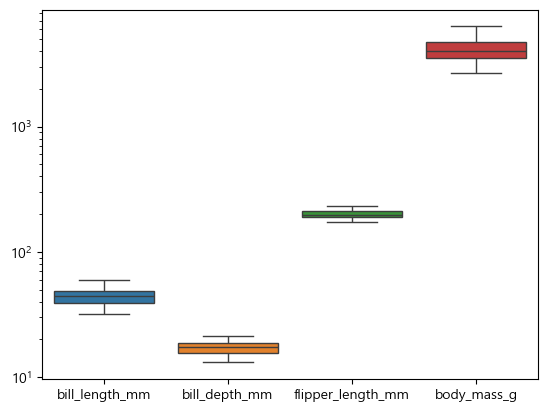

In [37]:
sns.boxplot(data=df)
plt.yscale('log')   #  1 2 3 4 5 6 .... 10   ->   # 1 10 100 1000 10000

In [45]:
df['island'].value_counts(normalize=True)

island
Biscoe       0.488372
Dream        0.360465
Torgersen    0.151163
Name: proportion, dtype: float64

<Axes: xlabel='sex', ylabel='count'>

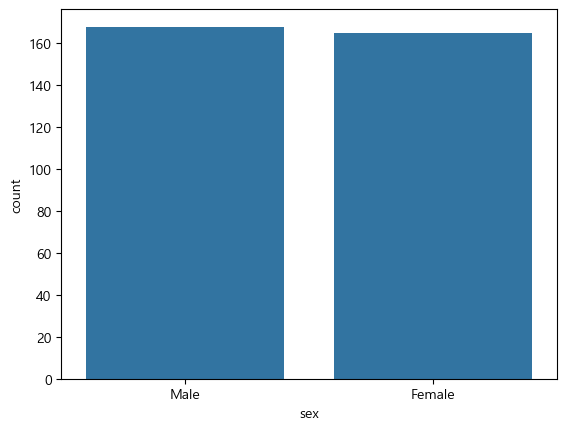

In [47]:
# 범주 데이터의 분포 확인
sns.countplot(data=df, x='sex')

In [52]:
df.isnull()   # false:0, true:1

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False
3,False,False,True,True,True,True,True
4,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...
339,False,False,True,True,True,True,True
340,False,False,False,False,False,False,False
341,False,False,False,False,False,False,False
342,False,False,False,False,False,False,False



일부 데이터에 결측이 있음



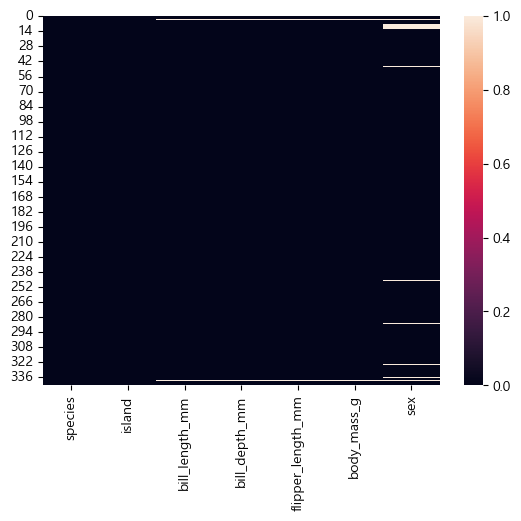

In [50]:
#결측값 확인
sns.heatmap(df.isnull())
print('''
일부 데이터에 결측이 있음
''')

In [56]:
df.isnull().sum()/ len(df)

species              0.000000
island               0.000000
bill_length_mm       0.005814
bill_depth_mm        0.005814
flipper_length_mm    0.005814
body_mass_g          0.005814
sex                  0.031977
dtype: float64

1. 결측값 처리
2. 수치형 데이터에 대한 처리
3. 범주형 데이터에 대한 인코딩

In [60]:
# 종속변수
y = df['species']
# 독립변수
X = df.drop(columns='species')
# X = df.drop(columns=['species', 'island', 'sex']) # 범주형 컬럼 제거
y.shape, X.shape

((344,), (344, 6))

In [62]:
df.columns

Index(['species', 'island', 'bill_length_mm', 'bill_depth_mm',
       'flipper_length_mm', 'body_mass_g', 'sex'],
      dtype='object')

In [64]:
y = df['species']
X = df[['island', 'bill_length_mm', 'bill_depth_mm','flipper_length_mm', 'body_mass_g', 'sex']]
y.shape, X.shape

((344,), (344, 6))

In [81]:
from sklearn.model_selection import train_test_split
# train_test_split() 함수로 데이터를 학습용과 테스트용으로 나눈다.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    stratify=y,
    test_size=0.3   # 7:3
    random_state=42  # 개발용
)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((258, 6), (86, 6), (258,), (86,))

In [92]:
# 컬럼 종류 구분
# df.columns
num_cols = ['bill_length_mm', 'bill_depth_mm','flipper_length_mm', 'body_mass_g']
cat_cols = ['island', 'sex']

In [123]:
# 결측값 처리
from sklearn.impute import SimpleImputer
si = SimpleImputer(strategy='median') # 중앙값으로 결측값을 대체 mean
X_train[num_cols] = si.fit_transform(X_train[num_cols])
X_test [num_cols] = si.    transform(X_test [num_cols])

In [128]:
# 카테고리 컬럼 데이터의 결측값 처리
si = SimpleImputer(strategy='most_frequent') # 최빈값으로 결측값을 대체
X_train[cat_cols] = si.fit_transform(X_train[cat_cols])
X_test [cat_cols] = si.    transform(X_test [cat_cols])

In [131]:
from sklearn.preprocessing import StandardScaler
ss = StandardScaler()
X_train[num_cols] = ss.fit_transform(X_train[num_cols])
X_test [num_cols] = ss.    transform(X_test [num_cols])

<Axes: >

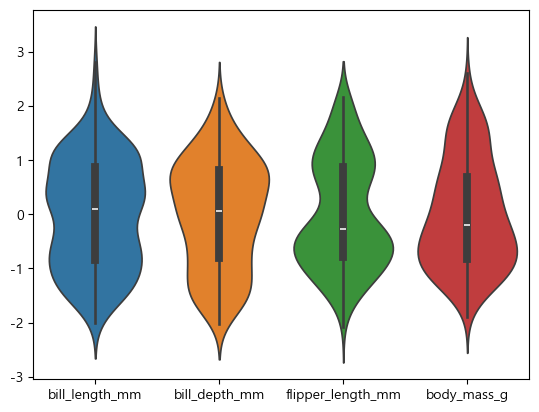

In [135]:
sns.violinplot(X_train)

In [138]:
from sklearn.preprocessing import OneHotEncoder
ohe = OneHotEncoder(sparse_output=False, drop='first', handle_unknown='ignore')
# 에러가 나는 경우 sparse=False로 대체
train_cat = ohe.fit_transform(X_train[cat_cols])
test_cat  = ohe.    transform(X_test [cat_cols])

In [145]:
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [157]:
train_cat = pd.DataFrame(train_cat, columns=ohe.get_feature_names_out(cat_cols), index=X_train.index)
test_cat  = pd.DataFrame(test_cat , columns=ohe.get_feature_names_out(cat_cols), index=X_test.index)
X_train = pd.concat([X_train.drop(columns=cat_cols), train_cat], axis=1)
X_test  = pd.concat([X_test .drop(columns=cat_cols), test_cat ], axis=1)

In [159]:
X_train

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,island_Dream,island_Torgersen,sex_Male
291,0.413886,-0.776452,1.448985,0.983635,0.0,0.0,1.0
144,-1.238982,-0.180248,-0.637888,-1.522503,1.0,0.0,0.0
212,1.412872,1.161212,0.369568,-0.332088,1.0,0.0,1.0
45,-0.821224,0.813426,-0.781811,0.482407,1.0,0.0,1.0
78,-1.438779,-0.528033,-0.997694,-0.833315,0.0,1.0,0.0
...,...,...,...,...,...,...,...
10,-1.148165,-0.031197,-1.069655,-1.146583,0.0,1.0,1.0
333,1.340218,-0.428666,2.096636,1.610170,0.0,0.0,1.0
75,-0.239996,0.664375,-0.422005,0.043833,0.0,1.0,1.0
82,-1.347962,0.813426,-0.997694,-0.520048,0.0,1.0,0.0


In [175]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(random_state=42)
# dt
dt.fit(X_train, y_train)
dt.score(X_train, y_train), dt.score(X_test, y_test)

(1.0, 0.9883720930232558)

In [180]:
from sklearn.linear_model import LogisticRegression
dt = LogisticRegression(max_iter=1000)
dt.fit(X_train, y_train)
dt.score(X_train, y_train), dt.score(X_test, y_test)

(0.9922480620155039, 1.0)